# Week 4 Pandas (Data Analysis, Cleaning & Correlation)

**Day 1**

## Assignment 46: Pandas Data Analysis

**Question:** Complete the exercise on data analysis with Pandas.


In [1]:
import pandas as pd
import numpy as np

# Create a small dataset (self-contained — no external file needed)
data = {
    "Duration": [60, 60, 60, 45, 45, 60, 60, 45, 30, 60, 60, 45],
    "Pulse":    [110, 117, 103, 109, 117, 102, 110, 104, 109, 98, 103, 100],
    "Maxpulse": [130, 145, 135, 175, 148, 127, 136, 155, 170, 122, 130, 120],
    "Calories": [409.1, 479.0, 340.0, 282.4, 406.0, 300.0, 374.0, 253.3, 195.1, 269.0, 380.0, 310.5],
}
df = pd.DataFrame(data)
df.to_csv("data.csv", index=False)
print("data.csv created.\n")

# Load it back
df = pd.read_csv("data.csv")
print(df)

data.csv created.

    Duration  Pulse  Maxpulse  Calories
0         60    110       130     409.1
1         60    117       145     479.0
2         60    103       135     340.0
3         45    109       175     282.4
4         45    117       148     406.0
5         60    102       127     300.0
6         60    110       136     374.0
7         45    104       155     253.3
8         30    109       170     195.1
9         60     98       122     269.0
10        60    103       130     380.0
11        45    100       120     310.5


In [3]:
print("First 5 rows:")
print(df.head(), "\n")

print("Last 5 rows:")
print(df.tail(), "\n")

print("DataFrame info:")
df.info()

First 5 rows:
   Duration  Pulse  Maxpulse  Calories
0        60    110       130     409.1
1        60    117       145     479.0
2        60    103       135     340.0
3        45    109       175     282.4
4        45    117       148     406.0 

Last 5 rows:
    Duration  Pulse  Maxpulse  Calories
7         45    104       155     253.3
8         30    109       170     195.1
9         60     98       122     269.0
10        60    103       130     380.0
11        45    100       120     310.5 

DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  12 non-null     int64  
 1   Pulse     12 non-null     int64  
 2   Maxpulse  12 non-null     int64  
 3   Calories  12 non-null     float64
dtypes: float64(1), int64(3)
memory usage: 512.0 bytes


In [ ]:
# Summary statistics
print("Mean of each numeric column:")
print(df.mean(numeric_only=True), "\n")

print("Median of each numeric column:")
print(df.median(numeric_only=True), "\n")

print("Mode of each numeric column:")
print(df.mode().iloc[0], "\n")

Mean of each numeric column:
Duration     52.500000
Pulse       106.833333
Maxpulse    141.083333
Calories    333.200000
dtype: float64 

Median of each numeric column:
Duration     60.00
Pulse       106.50
Maxpulse    135.50
Calories    325.25
dtype: float64 

Mode of each numeric column:
Duration     60.0
Pulse       103.0
Maxpulse    130.0
Calories    195.1
Name: 0, dtype: float64 



In [ ]:
# Grouping 
print("Average Pulse and Calories grouped by Duration:")
print(df.groupby("Duration")[["Pulse", "Calories"]].mean(), "\n")

Average Pulse and Calories grouped by Duration:
               Pulse    Calories
Duration                        
30        109.000000  195.100000
45        107.500000  313.050000
60        106.142857  364.442857 



## Assignment 46 Part B
### Part B: Extra practice examples

In [6]:
# Richer synthetic dataset
np.random.seed(42)
extra = pd.DataFrame({
    "Employee": [f"Emp{i}" for i in range(1, 21)],
    "Department": np.random.choice(["HR", "IT", "Sales", "Finance"], 20),
    "Salary": np.random.randint(30000, 120000, 20),
    "Experience": np.random.randint(1, 20, 20),
    "Performance": np.random.choice(["A", "B", "C"], 20),
})
print(extra.head(), "\n")

# describe() gives a full numeric summary
print("Full summary:")
print(extra.describe(), "\n")

  Employee Department  Salary  Experience Performance
0     Emp1      Sales   97221          19           B
1     Emp2    Finance   94820          12           A
2     Emp3         HR   30769           3           B
3     Emp4      Sales   89735           5           B
4     Emp5      Sales   92955          19           B 

Full summary:
              Salary  Experience
count      20.000000   20.000000
mean    82864.450000   10.300000
std     28483.426672    5.704107
min     30769.000000    2.000000
25%     57934.250000    6.500000
50%     93887.500000    9.000000
75%     98959.750000   15.000000
max    115305.000000   19.000000 



In [7]:
# value_counts on a categorical column
print("Employees per department:")
print(extra["Department"].value_counts(), "\n")

print("Performance grade counts:")
print(extra["Performance"].value_counts(), "\n")

Employees per department:
Department
Sales      9
Finance    6
HR         4
IT         1
Name: count, dtype: int64 

Performance grade counts:
Performance
B    15
C     3
A     2
Name: count, dtype: int64 



In [8]:
# Multi-aggregation groupby
print("Salary stats per department:")
print(extra.groupby("Department")["Salary"].agg(["mean", "min", "max", "count"]), "\n")

Salary stats per department:
                    mean    min     max  count
Department                                    
Finance     86974.166667  32747  114478      6
HR          53120.000000  30769   97969      4
IT          83707.000000  83707   83707      1
Sales       93250.777778  55658  115305      9 



In [9]:
# Filtering rows by condition
high_earners = extra[extra["Salary"] > 80000]
print("Employees earning more than 80,000:")
print(high_earners, "\n")

# Combining conditions
senior_high = extra[(extra["Salary"] > 60000) & (extra["Experience"] > 10)]
print("Senior high-earners:")
print(senior_high)

Employees earning more than 80,000:
   Employee Department  Salary  Experience Performance
0      Emp1      Sales   97221          19           B
1      Emp2    Finance   94820          12           A
3      Emp4      Sales   89735           5           B
4      Emp5      Sales   92955          19           B
5      Emp6    Finance   94925           7           B
6      Emp7         HR   97969           9           B
8      Emp9      Sales  113104          18           B
9     Emp10         IT   83707           4           A
10    Emp11      Sales  115305          14           C
12    Emp13      Sales  101932           9           B
14    Emp15    Finance  114478          15           B
17    Emp18    Finance   89150           8           C
18    Emp19    Finance   95725          15           C
19    Emp20      Sales  114654           3           B 

Senior high-earners:
   Employee Department  Salary  Experience Performance
0      Emp1      Sales   97221          19           B
1     

## Assignment 47: Pandas Data Cleaning

**Question:** Complete the exercise on Pandas data-cleaning techniques.


In [10]:
# Create a messy dataset
messy = pd.DataFrame({
    "Name":    ["Alice", "Bob", None, "Diana", "Eve", "Frank", "Grace", "Bob"],
    "Age":     [25, 30, 22, None, 29, 35, 28, 30],
    "Score":   ["88", "92", "75", "not_a_number", "81", None, "95", "92"],
    "City":    ["NY", "LA", "NY", "SF", None, "LA", "SF", "LA"],
})
messy.to_csv("messy.csv", index=False)
print("messy.csv created.\n")
print(messy, "\n")

messy.csv created.

    Name   Age         Score  City
0  Alice  25.0            88    NY
1    Bob  30.0            92    LA
2   None  22.0            75    NY
3  Diana   NaN  not_a_number    SF
4    Eve  29.0            81  None
5  Frank  35.0          None    LA
6  Grace  28.0            95    SF
7    Bob  30.0            92    LA 



In [11]:
# --- Audit missing values ---
print("Missing values per column:")
print(messy.isnull().sum(), "\n")

# --- Drop rows with any NaN ---
print("After dropna():")
print(messy.dropna(), "\n")

Missing values per column:
Name     1
Age      1
Score    1
City     1
dtype: int64 

After dropna():
    Name   Age Score City
0  Alice  25.0    88   NY
1    Bob  30.0    92   LA
6  Grace  28.0    95   SF
7    Bob  30.0    92   LA 



In [12]:
# --- Fill missing values instead ---
filled = messy.copy()
filled["Age"] = filled["Age"].fillna(filled["Age"].mean())
filled["City"] = filled["City"].fillna("Unknown")
filled["Name"] = filled["Name"].fillna("Anonymous")
print("After fillna():")
print(filled, "\n")

After fillna():
        Name        Age         Score     City
0      Alice  25.000000            88       NY
1        Bob  30.000000            92       LA
2  Anonymous  22.000000            75       NY
3      Diana  28.428571  not_a_number       SF
4        Eve  29.000000            81  Unknown
5      Frank  35.000000          None       LA
6      Grace  28.000000            95       SF
7        Bob  30.000000            92       LA 



In [13]:
# --- Fix wrong data type in Score column ---
filled["Score"] = pd.to_numeric(filled["Score"], errors="coerce")
filled["Score"] = filled["Score"].fillna(filled["Score"].mean())
print("Score column after cleaning:")
print(filled[["Name", "Score"]], "\n")

Score column after cleaning:
        Name      Score
0      Alice  88.000000
1        Bob  92.000000
2  Anonymous  75.000000
3      Diana  87.166667
4        Eve  81.000000
5      Frank  87.166667
6      Grace  95.000000
7        Bob  92.000000 



In [14]:
# --- Fix wrong data type in Score column ---
filled["Score"] = pd.to_numeric(filled["Score"], errors="coerce")
filled["Score"] = filled["Score"].fillna(filled["Score"].mean())
print("Score column after cleaning:")
print(filled[["Name", "Score"]], "\n")

Score column after cleaning:
        Name      Score
0      Alice  88.000000
1        Bob  92.000000
2  Anonymous  75.000000
3      Diana  87.166667
4        Eve  81.000000
5      Frank  87.166667
6      Grace  95.000000
7        Bob  92.000000 



In [15]:
# --- Remove duplicates ---
print("Duplicate rows:", filled.duplicated().sum(), "\n")
deduped = filled.drop_duplicates()
print("After drop_duplicates():")
print(deduped)

Duplicate rows: 1 

After drop_duplicates():
        Name        Age      Score     City
0      Alice  25.000000  88.000000       NY
1        Bob  30.000000  92.000000       LA
2  Anonymous  22.000000  75.000000       NY
3      Diana  28.428571  87.166667       SF
4        Eve  29.000000  81.000000  Unknown
5      Frank  35.000000  87.166667       LA
6      Grace  28.000000  95.000000       SF


## Assignment 47 Part B
### Part B: Extra practice examples


In [16]:
# Forward-fill vs backward-fill demo
ff = pd.DataFrame({"A": [1, None, None, 4, None, 6]})
print("Original:")
print(ff, "\n")

print("Forward fill:")
print(ff.ffill(), "\n")

print("Backward fill:")
print(ff.bfill(), "\n")

Original:
     A
0  1.0
1  NaN
2  NaN
3  4.0
4  NaN
5  6.0 

Forward fill:
     A
0  1.0
1  1.0
2  1.0
3  4.0
4  4.0
5  6.0 

Backward fill:
     A
0  1.0
1  4.0
2  4.0
3  4.0
4  6.0
5  6.0 



In [17]:
# String cleaning with .str methods
names = pd.DataFrame({
    "raw": ["  alice ", "BOB", "  Charlie", "diana  ", "EVE"]
})
names["cleaned"] = names["raw"].str.strip().str.title()
print(names, "\n")

         raw  cleaned
0     alice     Alice
1        BOB      Bob
2    Charlie  Charlie
3    diana      Diana
4        EVE      Eve 



In [18]:
# Type conversion with astype()
typed = pd.DataFrame({
    "id":   ["1", "2", "3", "4"],
    "flag": ["True", "False", "True", "False"],
})
typed["id"] = typed["id"].astype(int)
typed["flag"] = typed["flag"].astype(bool)
print(typed.dtypes, "\n")
print(typed)

id      int64
flag     bool
dtype: object 

   id  flag
0   1  True
1   2  True
2   3  True
3   4  True


In [19]:
# Replace specific bad values
bad = pd.DataFrame({"grade": ["A", "B", "?", "C", "N/A", "A"]})
bad["grade"] = bad["grade"].replace({"?": np.nan, "N/A": np.nan})
bad["grade"] = bad["grade"].fillna("Unknown")
print(bad)

     grade
0        A
1        B
2  Unknown
3        C
4  Unknown
5        A


## Assignment 48: Pandas Data Correlation

**Question:** Complete the exercise on data correlation with Pandas.

In [20]:
np.random.seed(0)
n = 100

# x and y are strongly positively correlated, z is negatively correlated,
# w is mostly noise (weak correlation)
x = np.random.rand(n)
y = x * 2 + np.random.normal(0, 0.1, n)
z = -x * 3 + np.random.normal(0, 0.2, n)
w = np.random.rand(n)

corr_df = pd.DataFrame({"x": x, "y": y, "z": z, "w": w})
print(corr_df.head(), "\n")

          x         y         z         w
0  0.548814  0.981112 -1.717239  0.882041
1  0.715189  1.520461 -2.420558  0.458604
2  0.602763  1.252093 -1.937014  0.724168
3  0.544883  0.936142 -2.079330  0.399025
4  0.423655  0.996135 -1.145918  0.904044 



In [21]:
# Full correlation matrix (default = Pearson)
print("Pearson correlation matrix:")
print(corr_df.corr(), "\n")

Pearson correlation matrix:
          x         y         z         w
x  1.000000  0.985310 -0.975967 -0.001954
y  0.985310  1.000000 -0.957113 -0.000599
z -0.975967 -0.957113  1.000000  0.004542
w -0.001954 -0.000599  0.004542  1.000000 



In [22]:
# Correlation of one column against all others
print("Correlation of 'x' with other columns:")
print(corr_df.corr()["x"], "\n")

Correlation of 'x' with other columns:
x    1.000000
y    0.985310
z   -0.975967
w   -0.001954
Name: x, dtype: float64 



In [23]:
# Other correlation methods
print("Spearman correlation:")
print(corr_df.corr(method="spearman"), "\n")

print("Kendall correlation:")
print(corr_df.corr(method="kendall"))

Spearman correlation:
          x         y         z         w
x  1.000000  0.983606 -0.974701  0.000372
y  0.983606  1.000000 -0.957828  0.007897
z -0.974701 -0.957828  1.000000 -0.008725
w  0.000372  0.007897 -0.008725  1.000000 

Kendall correlation:
          x         y         z         w
x  1.000000  0.889697 -0.867071  0.008081
y  0.889697  1.000000 -0.820606  0.006061
z -0.867071 -0.820606  1.000000 -0.010909
w  0.008081  0.006061 -0.010909  1.000000


## Assignment 48 Part B
### Part B: Extra practice examples

In [24]:
# Rounded correlation matrix for readability
print("Rounded to 2 decimals:")
print(corr_df.corr().round(2), "\n")

Rounded to 2 decimals:
      x     y     z    w
x  1.00  0.99 -0.98 -0.0
y  0.99  1.00 -0.96 -0.0
z -0.98 -0.96  1.00  0.0
w -0.00 -0.00  0.00  1.0 



In [25]:
# Interpreting: strong positive vs strong negative vs weak
corr_matrix = corr_df.corr().round(2)

for col in corr_matrix.columns:
    for other in corr_matrix.columns:
        if col < other:  # only print each pair once
            value = corr_matrix.loc[col, other]
            strength = (
                "strong positive" if value > 0.7 else
                "strong negative" if value < -0.7 else
                "moderate" if abs(value) > 0.3 else
                "weak"
            )
            print(f"{col} vs {other}: {value}  ->  {strength}")

x vs y: 0.99  ->  strong positive
x vs z: -0.98  ->  strong negative
y vs z: -0.96  ->  strong negative
w vs x: -0.0  ->  weak
w vs y: -0.0  ->  weak
w vs z: 0.0  ->  weak


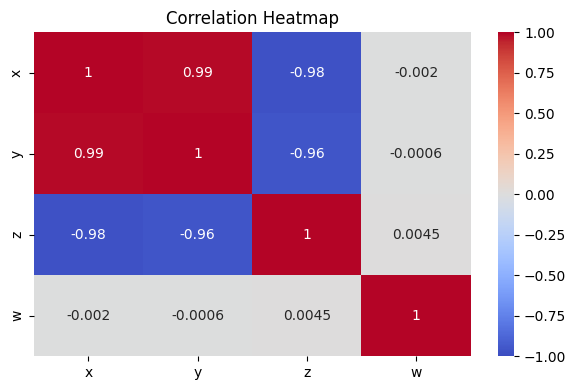

In [26]:
# Optional: heatmap visualization
try:
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 4))
    sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib / seaborn not installed — skipping heatmap.")